# METR-LA exploratory analysis

Los Angeles highway loop detectors (207 sensors, 5-minute speeds in mph, March to June 2012).
This notebook checks data quality and the statistics the platform relies on: free-flow speed
(85th percentile), the weekly expected-speed profile (median per weekday x 5-min slot) and the
sensor selection used by `N_SENSORS`.

In [1]:
import json
import sys
from pathlib import Path

ROOT = Path.cwd().parents[1] if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path[:0] = [str(ROOT), str(ROOT / 'common')]
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ml.dataset import read_locations, read_metr_la_h5, split_points

plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#e1e0d9', 'grid.linewidth': 0.6,
                     'axes.edgecolor': '#c3c2b7', 'axes.labelcolor': '#52514e',
                     'xtick.color': '#898781', 'ytick.color': '#898781', 'lines.linewidth': 2})
BLUE, ORANGE, GREY = '#2a78d6', '#eb6834', '#898781'
df = read_metr_la_h5(ROOT / 'data' / 'metr-la.h5')
loc = read_locations(ROOT / 'data' / 'graph_sensor_locations.csv')
meta = json.loads((ROOT / 'data' / 'processed' / 'sensor_meta.json').read_text())
print(df.shape, df.index.min(), '->', df.index.max())

(34272, 207) 2012-03-01 00:00:00 -> 2012-06-27 23:55:00


## Missing values
METR-LA encodes a missing reading as speed 0. They are masked (NaN) everywhere.

missing readings: 8.1%
worst sensors:
718076    20.1%
716939    18.9%
760987    16.1%
716955    15.7%
769418    15.6%
dtype: str


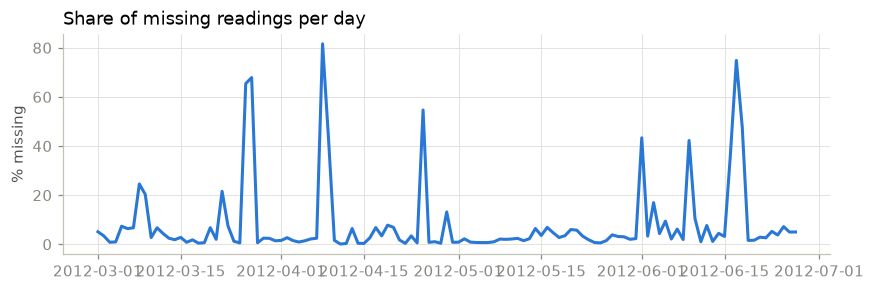

In [2]:
zero = (df == 0)
print(f"missing readings: {zero.values.mean():.1%}")
per_sensor = zero.mean().sort_values(ascending=False)
print("worst sensors:"); print(per_sensor.head(5).map('{:.1%}'.format))
daily = zero.mean(axis=1).resample('D').mean()
fig, ax = plt.subplots(figsize=(9, 2.6))
ax.plot(daily.index, daily * 100, color=BLUE)
ax.set_ylabel('% missing'); ax.set_title('Share of missing readings per day', loc='left')
plt.show()

## Daily patterns
Weekday rush hours (morning and evening) against flat weekends.

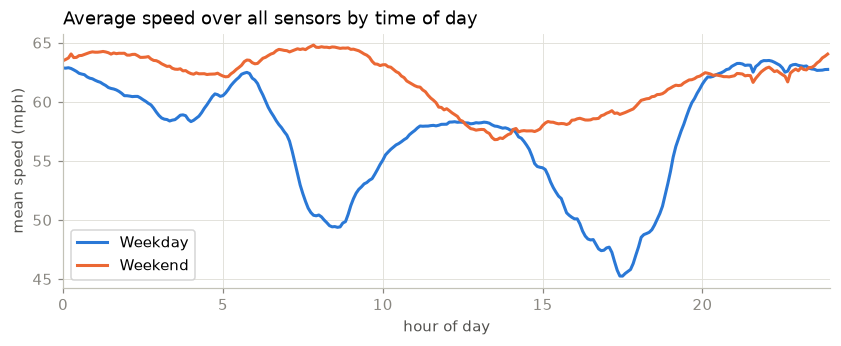

In [3]:
sp = df.replace(0, np.nan)
tod = sp.index.hour + sp.index.minute / 60
weekday = sp[sp.index.day_of_week < 5].mean(axis=1).groupby(tod[sp.index.day_of_week < 5]).mean()
weekend = sp[sp.index.day_of_week >= 5].mean(axis=1).groupby(tod[sp.index.day_of_week >= 5]).mean()
fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(weekday.index, weekday.values, color=BLUE, label='Weekday')
ax.plot(weekend.index, weekend.values, color=ORANGE, label='Weekend')
ax.set_xlabel('hour of day'); ax.set_ylabel('mean speed (mph)'); ax.set_xlim(0, 24)
ax.set_title('Average speed over all sensors by time of day', loc='left'); ax.legend(loc='lower left')
plt.show()

## Sensor map
All 207 detectors; the `N_SENSORS` selection (closest to the network centre) is highlighted.

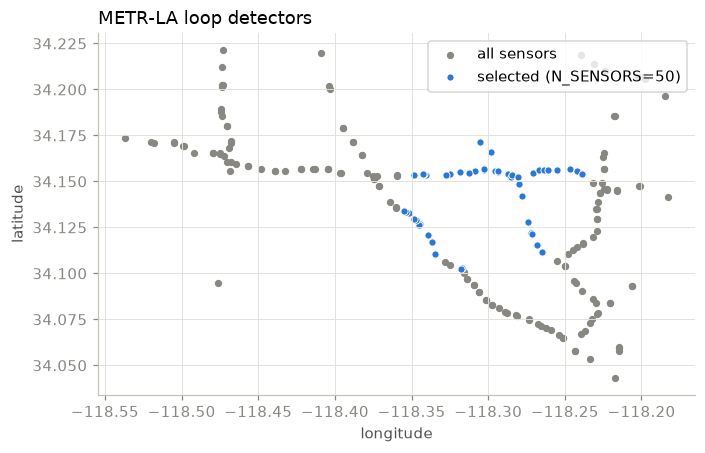

In [4]:
sel = [m['sensor_id'] for m in meta['sensors']]
fig, ax = plt.subplots(figsize=(7, 5.5))
ax.scatter(loc['lon'], loc['lat'], s=14, color=GREY, label='all sensors')
ax.scatter(loc.loc[sel, 'lon'], loc.loc[sel, 'lat'], s=22, color=BLUE, edgecolor='white', linewidth=.6,
           label=f'selected (N_SENSORS={len(sel)})')
ax.set_xlabel('longitude'); ax.set_ylabel('latitude'); ax.set_aspect(1.2); ax.legend(loc='upper right')
ax.set_title('METR-LA loop detectors', loc='left'); plt.show()

## Free-flow speed
85th percentile of the training period (first 70 % of time), per sensor.

count    50.0
mean     66.1
std       3.1
min      53.8
25%      64.9
50%      67.3
75%      68.4
max      69.4
dtype: float64


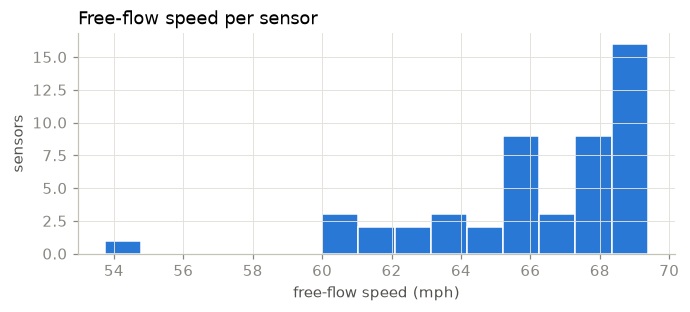

In [5]:
ff = pd.Series({m['sensor_id']: m['free_flow_mph'] for m in meta['sensors']})
print(ff.describe().round(1))
fig, ax = plt.subplots(figsize=(7, 2.6))
ax.hist(ff, bins=15, color=BLUE, edgecolor='white')
ax.set_xlabel('free-flow speed (mph)'); ax.set_ylabel('sensors'); ax.set_title('Free-flow speed per sensor', loc='left')
plt.show()

## Expected travel-time profile
Median speed per weekday x 5-min slot gives the *expected* travel time; delay = actual - expected.

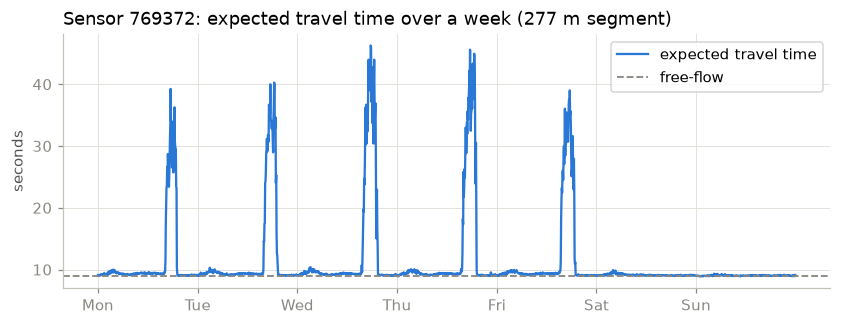

In [6]:
m = max(meta['sensors'], key=lambda s: s['free_flow_mph'] - min(s['expected_speed']))
exp = np.array(m['expected_speed']); seg = m['segment_length_m']
tt = seg / (exp * 0.44704)
fig, ax = plt.subplots(figsize=(9, 3))
x = np.arange(2016) / 288
ax.plot(x, tt, color=BLUE, linewidth=1.5, label='expected travel time')
ax.axhline(seg / (m['free_flow_mph'] * 0.44704), color=GREY, linestyle='--', linewidth=1.2, label='free-flow')
ax.set_xticks(range(7), ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun'])
ax.set_ylabel('seconds'); ax.legend(loc='upper right')
ax.set_title(f"Sensor {m['sensor_id']}: expected travel time over a week ({seg:.0f} m segment)", loc='left')
plt.show()

## Congestion levels by hour
Share of readings per level with the default thresholds (0.2 / 0.4 / 0.6).

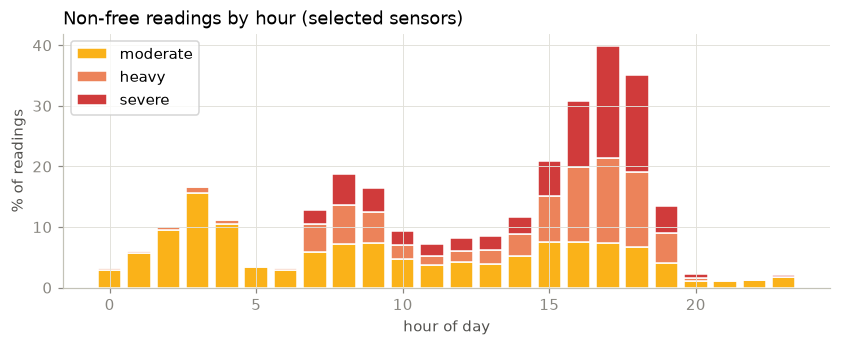

train until 2012-05-23 07:05:00 | validation until 2012-06-04 04:40:00 | test from 2012-06-04 04:45:00


In [7]:
ffv = pd.Series({m['sensor_id']: m['free_flow_mph'] for m in meta['sensors']})
s = sp[sel]
ci = (1 - s / ffv).clip(lower=0)
lv = pd.cut(ci.stack(), [-1, .2, .4, .6, 10], labels=['free', 'moderate', 'heavy', 'severe'], right=False)
hour = lv.index.get_level_values(0).hour
share = pd.crosstab(hour, lv, normalize='index') * 100
colors = {'free': '#0ca30c', 'moderate': '#fab219', 'heavy': '#ec835a', 'severe': '#d03b3b'}
fig, ax = plt.subplots(figsize=(9, 3))
bottom = np.zeros(len(share))
for col in ['moderate', 'heavy', 'severe']:
    ax.bar(share.index, share[col], bottom=bottom, color=colors[col], label=col, edgecolor='white', linewidth=1)
    bottom += share[col].values
ax.set_xlabel('hour of day'); ax.set_ylabel('% of readings'); ax.legend(loc='upper left')
ax.set_title('Non-free readings by hour (selected sensors)', loc='left'); plt.show()
n_train, n_val = split_points(len(df))
print('train until', df.index[n_train - 1], '| validation until', df.index[n_val - 1], '| test from', df.index[n_val])